In [2]:
from pathlib import Path
import os
import joblib
import pandas as pd

PROJECT_DIR = Path.cwd()

print("Current folder:", PROJECT_DIR)
print("\nFiles in current folder:")
for file in PROJECT_DIR.iterdir():
    print(file.name)

model_paths = {
    "Logistic Regression": PROJECT_DIR / "logistic_regression_model.pkl",
    "Random Forest": PROJECT_DIR / "random_forest.pkl",
    "XGBoost": PROJECT_DIR / "xgboost.pkl"
}

print("\nModel file verification:")
for name, path in model_paths.items():
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

Current folder: C:\Users\Aahana\Customer_Churn

Files in current folder:
.ipynb_checkpoints
04_random_forest.ipynb
05_xgboost.ipynb
06_model_comparison.ipynb
logistic_regression.ipynb
logistic_regression_model.pkl
random_forest.pkl
telco_processed.csv
xgboost.pkl

Model file verification:
Logistic Regression: Found
Random Forest: Found
XGBoost: Found


In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
HOME_DIR = Path.home()

print("CSV files inside project:")
for p in PROJECT_DIR.rglob("*.csv"):
    print(p)

print("\nCSV files in common folders:")
for folder_name in ["Downloads", "Desktop", "Documents"]:
    folder = HOME_DIR / folder_name
    if folder.exists():
        for p in folder.glob("*.csv"):
            print(p)

CSV files inside project:
C:\Users\Aahana\Customer_Churn\telco_processed.csv

CSV files in common folders:
C:\Users\Aahana\Downloads\telco_processed.csv


In [4]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()

DATA_PATH = PROJECT_DIR / "telco_processed.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget column candidates:")
for col in df.columns:
    if "churn" in col.lower():
        print(col, ":", df[col].unique()[:10])

Dataset shape: (7043, 20)

Column names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Data types:
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "telco_processed.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (7043, 20)


In [5]:
print("Total columns:", len(df.columns))
print("\nColumn names:")

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

Total columns: 20

Column names:
1. gender
2. SeniorCitizen
3. Partner
4. Dependents
5. tenure
6. PhoneService
7. MultipleLines
8. InternetService
9. OnlineSecurity
10. OnlineBackup
11. DeviceProtection
12. TechSupport
13. StreamingTV
14. StreamingMovies
15. Contract
16. PaperlessBilling
17. PaymentMethod
18. MonthlyCharges
19. TotalCharges
20. Churn


In [6]:
display(df.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("DATA TYPES")
display(df.dtypes.to_frame("Data Type"))

print("\nMISSING VALUES")
display(df.isnull().sum().to_frame("Missing Count"))

DATA TYPES


,Data Type
gender,object
SeniorCitizen,object
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object



MISSING VALUES


,Missing Count
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [10]:
print("Possible target columns:")

for col in df.columns:
    if "churn" in col.lower():
        print(f"\nColumn: {col}")
        print("Unique values:", df[col].unique()[:20])
        print("\nValue counts:")
        display(df[col].value_counts(dropna=False))

Possible target columns:

Column: Churn
Unique values: ['No' 'Yes']

Value counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [8]:
from pathlib import Path
import joblib

PROJECT_DIR = Path.cwd()

model_paths = {
    "Logistic Regression": PROJECT_DIR / "logistic_regression_model.pkl",
    "Random Forest": PROJECT_DIR / "random_forest.pkl",
    "XGBoost": PROJECT_DIR / "xgboost.pkl"
}

models = {}

for name, path in model_paths.items():
    models[name] = joblib.load(path)
    print(f"{name}: loaded successfully")

Logistic Regression: loaded successfully
Random Forest: loaded successfully


C:\Users\Aahana\anaconda3\envs\cnn-env\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Aahana\anaconda3\envs\cnn-env\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Aahana\anaconda3\envs\cnn-env\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.8.0 when using version

XGBoost: loaded successfully


C:\Users\Aahana\anaconda3\envs\cnn-env\lib\pickle.py:1718: UserWarning: [00:34:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


In [9]:
import sklearn
import sys
import joblib

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

try:
    import xgboost
    print("XGBoost:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed in this environment.")

Python: C:\Users\Aahana\anaconda3\envs\cnn-env\python.exe
scikit-learn: 1.7.2
joblib: 1.5.3
XGBoost: 3.2.0


In [13]:
%pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 3.4 MB/s eta 0:00:31
    --------------------------------------- 1.3/101.7 MB 3.7 MB/s eta 0:00:27
    --------------------------------------- 2.4/101.7 MB 3.9 MB/s eta 0:00:26
   - -------------------------------------- 3.1/101.7 MB 4.0 MB/s eta 0:00:25
   - -------------------------------------- 4.2/101.7 MB 4.1 MB/s eta 0:00:25
   - -------------------------------------- 5.0/101.7 MB 4.1 MB/s eta 0:00:24
   -- ------------------------------------- 6.0/101.7 MB 4.2 MB/s eta 0:00:23
   -- ------------------------------------- 7.1/101.7 MB 4.3 MB/s eta 0:00:22
   --- ------------------------------------ 7.9/101.7 MB 4.3 MB/s eta 0:00:22
   --- ------------------------------------ 8.7/101.7 MB 4.3 MB/s eta 0:00:22
   --- ------------------------------------ 9.4/101.7 MB 4.2 MB/s eta 0:00:22
   --- ------------------------------------ 9.7/101.7 MB 4.2 MB/s eta 0

In [10]:
print("Dataset shape:", df.shape)
print("Loaded models:", list(models.keys()))
print("Dataset columns:", df.columns.tolist())

Dataset shape: (7043, 20)
Loaded models: ['Logistic Regression', 'Random Forest', 'XGBoost']
Dataset columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [11]:
lr_model = models["Logistic Regression"]

print("Model type:", type(lr_model))
print("Pipeline steps:")

if hasattr(lr_model, "named_steps"):
    for step_name, step_object in lr_model.named_steps.items():
        print(step_name, "->", type(step_object).__name__)
else:
    print("This model is not a pipeline.")

Model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps:
preprocessor -> ColumnTransformer
classifier -> LogisticRegression


In [12]:
rf_model = models["Random Forest"]

print("Model type:", type(rf_model))

if hasattr(rf_model, "named_steps"):
    for step_name, step_object in rf_model.named_steps.items():
        print(step_name, "->", type(step_object).__name__)
else:
    print("This model is not a pipeline.")

Model type: <class 'sklearn.pipeline.Pipeline'>
preprocessor -> ColumnTransformer
classifier -> RandomForestClassifier


In [13]:
xgb_model = models["XGBoost"]

print("Model type:", type(xgb_model))

if hasattr(xgb_model, "named_steps"):
    for step_name, step_object in xgb_model.named_steps.items():
        print(step_name, "->", type(step_object).__name__)
else:
    print("This model is not a pipeline.")

Model type: <class 'sklearn.pipeline.Pipeline'>
preprocessor -> ColumnTransformer
classifier -> XGBClassifier


In [15]:
import json
from pathlib import Path

for filename in [
    "03_logistic_regression.ipynb",
    "04_random_forest.ipynb",
    "05_xgboost.ipynb"
]:
    path = Path.cwd() / filename
    print(f"\n{'=' * 55}\n{filename}\n{'=' * 55}")

    if path.exists():
        notebook = json.loads(path.read_text(encoding="utf-8"))
        for cell in notebook.get("cells", []):
            if cell.get("cell_type") == "code":
                source = "".join(cell.get("source", []))
                if any(term in source.lower() for term in [
                    "train_test_split", "random_state", "x_test",
                    "x_train", "test_size", "stratify"
                ]):
                    print(source[:1800])
                    print("-" * 30)
    else:
        print("Notebook file not found.")


03_logistic_regression.ipynb
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import joblib


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score, 
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries Imported Successfully")
------------------------------
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size = 0.20, 
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :" , len(X_test))
------------------------------
model = Pipeline(steps=[
    ("preprocessor", preproce

In [16]:
print("Dataset shape:", df.shape)
print("\nColumns:")
for col in df.columns:
    print(col)

required = ["customerID", "Churn", "ChurnFlag", "tenure_group", "charges_group"]
print("\nRequired columns:")
for col in required:
    print(f"{col}: {col in df.columns}")

Dataset shape: (7043, 20)

Columns:
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn

Required columns:
customerID: False
Churn: True
ChurnFlag: False
tenure_group: False
charges_group: False


In [17]:
for name, model in models.items():
    print(f"\n{'=' * 40}\n{name}")
    if hasattr(model, "feature_names_in_"):
        print("Features:", list(model.feature_names_in_))
    elif hasattr(model, "named_steps"):
        prep = model.named_steps.get("preprocessor")
        if prep is not None and hasattr(prep, "feature_names_in_"):
            print("Features:", list(prep.feature_names_in_))
        else:
            print("Input feature names are not available.")
    else:
        print("Inspect model's input requirements manually.")


Logistic Regression
Features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Random Forest
Features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

XGBoost
Features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [18]:
for col in ["Churn", "ChurnFlag"]:
    if col in df.columns:
        print(f"\n{col} value counts:")
        print(df[col].value_counts(dropna=False))
    else:
        print(f"\n{col} is missing from the dataset.")


Churn value counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

ChurnFlag is missing from the dataset.


In [19]:
from pathlib import Path

search_terms = [
    "*test_predictions.csv",
    "*metrics.csv",
    "*metrics.json"
]

for pattern in search_terms:
    print(f"\nFiles matching {pattern}:")
    matches = list(Path.cwd().rglob(pattern))
    if matches:
        for path in matches:
            print(path)
    else:
        print("None found.")


Files matching *test_predictions.csv:
None found.

Files matching *metrics.csv:
None found.

Files matching *metrics.json:
None found.


In [20]:
print("Current dataset shape:", df.shape)
print("\nCurrent dataset columns:")
print(df.columns.tolist())

Current dataset shape: (7043, 20)

Current dataset columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [21]:
print("Loaded models:")
for name, model in models.items():
    print(f"{name}: {type(model).__name__}")

Loaded models:
Logistic Regression: Pipeline
Random Forest: Pipeline
XGBoost: Pipeline


In [22]:
for name, model in models.items():
    print(f"\n--- {name} ---")
    if hasattr(model, "feature_names_in_"):
        print("Expected features:", list(model.feature_names_in_))
    elif hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps.keys()))
        for step_name, step in model.named_steps.items():
            if hasattr(step, "feature_names_in_"):
                print(f"{step_name} input features:", list(step.feature_names_in_))
    else:
        print("Input feature names are not directly available.")


--- Logistic Regression ---
Expected features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

--- Random Forest ---
Expected features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

--- XGBoost ---
Expected features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Mont

In [23]:
for col in ["Churn", "ChurnFlag"]:
    if col in df.columns:
        print(f"\n{col} data type:", df[col].dtype)
        print(df[col].value_counts(dropna=False))
    else:
        print(f"\n{col} is missing.")


Churn data type: object
Churn
No     5174
Yes    1869
Name: count, dtype: int64

ChurnFlag is missing.


In [24]:
from pathlib import Path

print("CSV files in the project folder:")
for path in sorted(Path.cwd().glob("*.csv")):
    print(path.name)

CSV files in the project folder:
telco_processed.csv


In [25]:
target_col = "Churn"
X = df.drop(columns=[target_col]).copy()
y = df[target_col].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target missing values:", y.isna().sum())
print("Target classes:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)
Target missing values: 0
Target classes:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [26]:
for name, model in models.items():
    expected = list(model.feature_names_in_)
    print(f"\n{name}")
    print("Missing features:", [c for c in expected if c not in X.columns])
    print("Extra features:", [c for c in X.columns if c not in expected])
    print("Feature order matches:", list(X.columns) == expected)


Logistic Regression
Missing features: []
Extra features: []
Feature order matches: True

Random Forest
Missing features: []
Extra features: []
Feature order matches: True

XGBoost
Missing features: []
Extra features: []
Feature order matches: True


In [27]:
expected_features = list(models["Logistic Regression"].feature_names_in_)

if set(X.columns) == set(expected_features):
    X = X[expected_features].copy()
    print("Feature columns matched and reordered.")
else:
    print("Feature mismatch detected. Do not run predictions yet.")

Feature columns matched and reordered.


In [28]:
print("Missing values per feature:")
print(X.isna().sum())

print("\nFeature data types:")
print(X.dtypes)

Missing values per feature:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

Feature data types:
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges    

In [29]:
import sklearn
import xgboost

print("Scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)

for name, model in models.items():
    print(f"{name}: loaded as {type(model).__name__}")

Scikit-learn version: 1.7.2
XGBoost version: 3.2.0
Logistic Regression: loaded as Pipeline
Random Forest: loaded as Pipeline
XGBoost: loaded as Pipeline


In [30]:
from sklearn.model_selection import train_test_split

assert y.notna().all(), "Target contains missing values."
assert X.columns.tolist() == expected_features, "Feature order mismatch."

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTest target distribution:")
print(y_test.value_counts())

Training samples: 5634
Testing samples: 1409

Test target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [31]:
predictions = {}
probabilities = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name}: predictions generated")

Logistic Regression: predictions generated
Random Forest: predictions generated
XGBoost: predictions generated


In [32]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

results = []

for name in models:
    pred = predictions[name]
    prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

print("Metrics calculated for all models.")

Metrics calculated for all models.


In [33]:
import pandas as pd

comparison_df = pd.DataFrame(results).set_index("Model")
display(comparison_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415
Random Forest,0.7537,0.5242,0.7834,0.6281,0.8442
XGBoost,0.7424,0.5094,0.7995,0.6223,0.8443


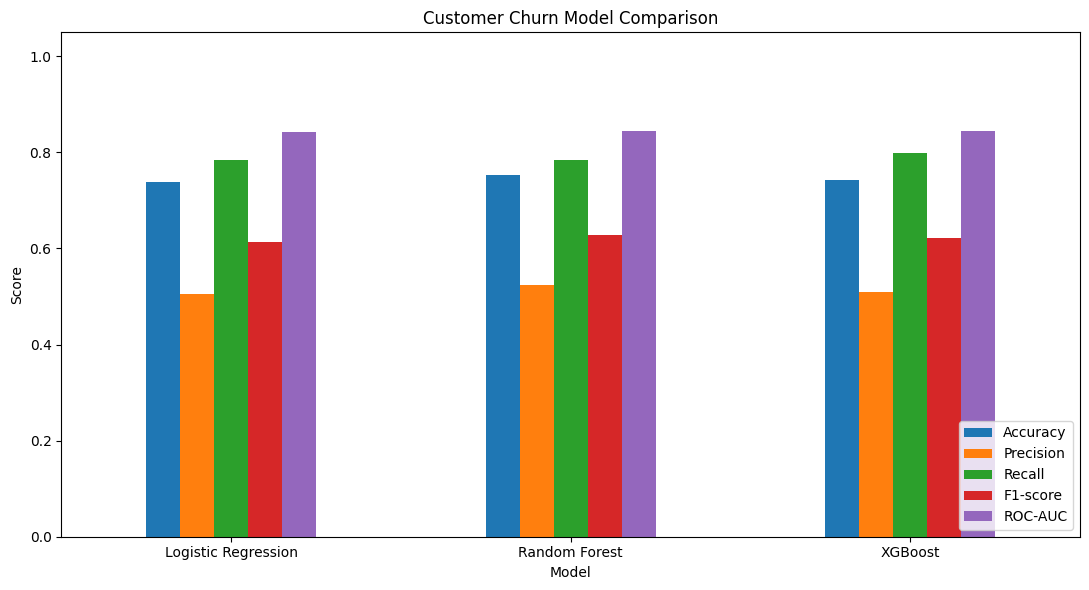

In [34]:
import matplotlib.pyplot as plt

comparison_df.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Customer Churn Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [35]:
from pathlib import Path

output_dir = Path.cwd()

comparison_df.to_csv(output_dir / "model_comparison.csv")

print("Saved:", output_dir / "model_comparison.csv")

Saved: C:\Users\Aahana\Customer_Churn\model_comparison.csv


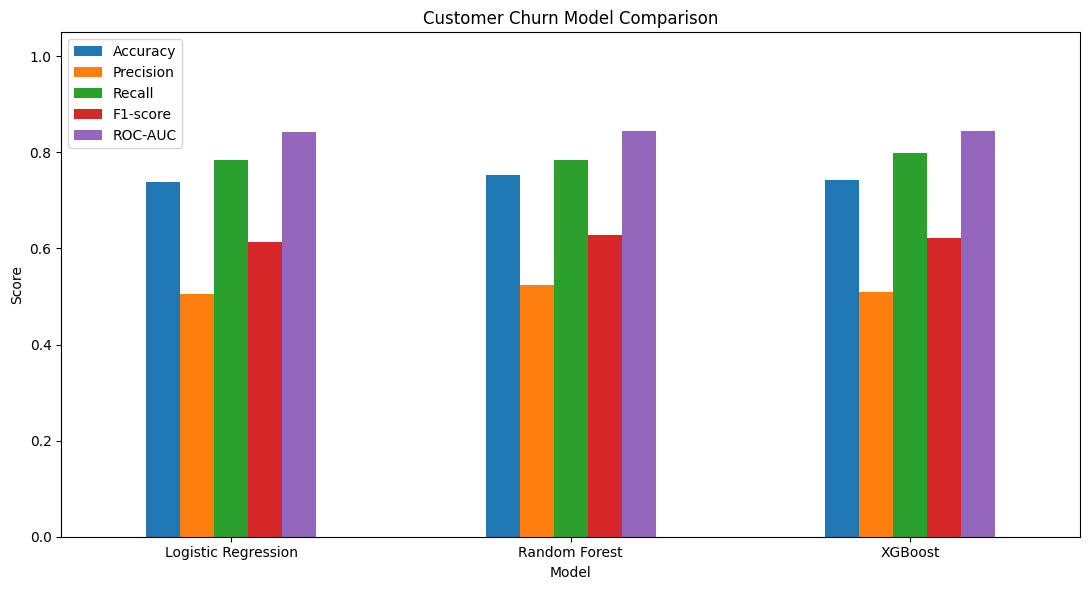

Saved: C:\Users\Aahana\Customer_Churn\model_comparison.png


In [36]:
import matplotlib.pyplot as plt

ax = comparison_df.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
ax.set_title("Customer Churn Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()

chart_path = output_dir / "model_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_path)

In [37]:
print("Best model by metric:\n")

for metric in comparison_df.columns:
    best_model = comparison_df[metric].idxmax()
    best_score = comparison_df.loc[best_model, metric]
    print(f"{metric}: {best_model} ({best_score:.4f})")

Best model by metric:

Accuracy: Random Forest (0.7537)
Precision: Random Forest (0.5242)
Recall: XGBoost (0.7995)
F1-score: Random Forest (0.6281)
ROC-AUC: XGBoost (0.8443)


In [38]:
best_model_name = comparison_df["F1-score"].idxmax()

final_predictions = pd.DataFrame({
    "dataset_row_index": X_test.index,
    "actual_churn": y_test.to_numpy(),
    "predicted_churn": predictions[best_model_name],
    "churn_probability": probabilities[best_model_name]
})

print("Selected by F1-score:", best_model_name)
display(final_predictions.head())
print("Prediction rows:", len(final_predictions))

Selected by F1-score: Random Forest


,dataset_row_index,actual_churn,predicted_churn,churn_probability
0,437,0,0,0.047979
1,2280,0,1,0.837111
2,2235,0,0,0.155531
3,4460,0,1,0.639595
4,3761,0,0,0.067717


Prediction rows: 1409


In [39]:
predictions_path = output_dir / "final_predictions.csv"

final_predictions.to_csv(predictions_path, index=False)

print("Saved:", predictions_path)
print("Columns:", final_predictions.columns.tolist())
print("File exists:", predictions_path.exists())

Saved: C:\Users\Aahana\Customer_Churn\final_predictions.csv
Columns: ['dataset_row_index', 'actual_churn', 'predicted_churn', 'churn_probability']
File exists: True


In [40]:
from pathlib import Path

for filename in [
    "model_comparison.csv",
    "model_comparison.png",
    "final_predictions.csv"
]:
    path = Path(filename)
    print(f"{filename}: {'Exists' if path.exists() else 'Missing'}")
    if path.exists():
        print(f"  Size: {path.stat().st_size:,} bytes")

model_comparison.csv: Exists
  Size: 378 bytes
model_comparison.png: Exists
  Size: 97,656 bytes
final_predictions.csv: Exists
  Size: 41,364 bytes


In [41]:
saved_comparison = pd.read_csv("model_comparison.csv")
display(saved_comparison)
print("Shape:", saved_comparison.shape)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841502
1,Random Forest,0.753726,0.524150,0.783422,0.628081,0.844163
2,XGBoost,0.742370,0.509370,0.799465,0.622268,0.844333


Shape: (3, 6)


In [42]:
saved_predictions = pd.read_csv("final_predictions.csv")

print("Shape:", saved_predictions.shape)
print("Columns:", saved_predictions.columns.tolist())
print("\nMissing values:")
print(saved_predictions.isna().sum())

Shape: (1409, 4)
Columns: ['dataset_row_index', 'actual_churn', 'predicted_churn', 'churn_probability']

Missing values:
dataset_row_index    0
actual_churn         0
predicted_churn      0
churn_probability    0
dtype: int64


In [43]:
print("Actual churn counts:")
print(saved_predictions["actual_churn"].value_counts())

print("\nPredicted churn counts:")
print(saved_predictions["predicted_churn"].value_counts())

print("\nAverage predicted churn probability:",
      round(saved_predictions["churn_probability"].mean(), 4))

Actual churn counts:
actual_churn
0    1035
1     374
Name: count, dtype: int64

Predicted churn counts:
predicted_churn
0    850
1    559
Name: count, dtype: int64

Average predicted churn probability: 0.404


In [44]:
from pathlib import Path

project_dir = Path.cwd()

print("Project folder:", project_dir)
print("\nFiles available:")
for path in sorted(project_dir.iterdir()):
    if path.is_file():
        print(path.name)

Project folder: C:\Users\Aahana\Customer_Churn

Files available:
03_logistic_regression.ipynb
04_random_forest.ipynb
05_xgboost.ipynb
06_model_comparison.ipynb
final_predictions.csv
logistic_regression_model.pkl
model_comparison.csv
model_comparison.png
random_forest.pkl
telco_processed.csv
xgboost.pkl


In [45]:
from sklearn.metrics import classification_report

print("Selected model:", best_model_name)
print(classification_report(
    y_test,
    predictions[best_model_name],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Selected model: Random Forest
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.82      1035
       Churn       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



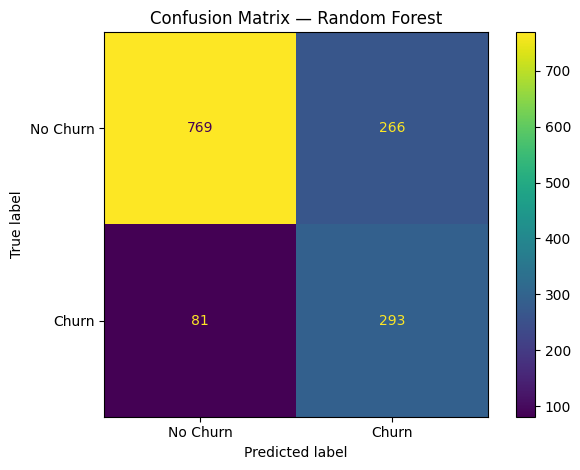

Confusion matrix:
 [[769 266]
 [ 81 293]]


In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions[best_model_name])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(values_format="d")

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

print("Confusion matrix:\n", cm)

In [47]:
comparison_export = comparison_df.reset_index()
comparison_export.to_csv("model_comparison.csv", index=False)

print("Updated model_comparison.csv")
display(comparison_export.round(4))

Updated model_comparison.csv


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415
1,Random Forest,0.7537,0.5242,0.7834,0.6281,0.8442
2,XGBoost,0.7424,0.5094,0.7995,0.6223,0.8443


In [48]:
recommendation = """
MODEL COMPARISON — CUSTOMER CHURN PREDICTION

Models compared:
1. Logistic Regression
2. Random Forest
3. XGBoost

Preliminary results:
- Random Forest achieved the highest accuracy (75.37%) and F1-score (0.6281).
- XGBoost achieved the highest recall (79.95%) and ROC-AUC (0.8443).
- Logistic Regression provides a baseline for comparison.

Recommendation:
Random Forest is the preliminary choice when balancing precision and recall
using F1-score. XGBoost is worth considering when identifying more customers
at risk of churn is the priority.

Important limitation:
These results should be treated as preliminary until the evaluation split
and scikit-learn environment are verified against the original training setup.
"""

print(recommendation)

with open("model_recommendation.txt", "w", encoding="utf-8") as file:
    file.write(recommendation)

print("Saved model_recommendation.txt")


MODEL COMPARISON — CUSTOMER CHURN PREDICTION

Models compared:
1. Logistic Regression
2. Random Forest
3. XGBoost

Preliminary results:
- Random Forest achieved the highest accuracy (75.37%) and F1-score (0.6281).
- XGBoost achieved the highest recall (79.95%) and ROC-AUC (0.8443).
- Logistic Regression provides a baseline for comparison.

Recommendation:
Random Forest is the preliminary choice when balancing precision and recall
using F1-score. XGBoost is worth considering when identifying more customers
at risk of churn is the priority.

Important limitation:
These results should be treated as preliminary until the evaluation split
and scikit-learn environment are verified against the original training setup.

Saved model_recommendation.txt


In [49]:
from pathlib import Path

required_files = [
    "06_model_comparison.ipynb",
    "model_comparison.csv",
    "final_predictions.csv",
    "model_comparison.png",
    "model_recommendation.txt"
]

for filename in required_files:
    path = Path(filename)
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

06_model_comparison.ipynb: OK
model_comparison.csv: OK
final_predictions.csv: OK
model_comparison.png: OK
model_recommendation.txt: OK


In [50]:
from pathlib import Path

for filename in [
    "03_logistic_regression.ipynb",
    "04_random_forest.ipynb",
    "05_xgboost.ipynb"
]:
    print(filename, ":", Path(filename).exists())

03_logistic_regression.ipynb : True
04_random_forest.ipynb : True
05_xgboost.ipynb : True


In [51]:
import json

for filename in [
    "03_logistic_regression.ipynb",
    "04_random_forest.ipynb",
    "05_xgboost.ipynb"
]:
    print(f"\n{'=' * 15} {filename} {'=' * 15}")
    notebook = json.loads(Path(filename).read_text(encoding="utf-8"))

    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])
        if any(term in source for term in [
            "train_test_split", "read_csv", "ChurnFlag",
            "joblib.dump", "to_csv"
        ]):
            print(source[:1800], "\n")


=============== 03_logistic_regression.ipynb ===============
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import joblib


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score, 
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries Imported Successfully") 

# LOAD DATASET from zip file 


zip_path = r"C:\Users\DELL\Downloads\logistic_reg\02_M2_EDA-20261005T165806Z-1-001.zip"

with zipfile.ZipFile(zip_path , "r")  as archive:
    csv_file = next (
        name for name in archive.namelist()
        if name.endswith("telco_with_ids.csv")
    )
    wi

In [52]:
feature_lists = {
    name: list(model.feature_names_in_)
    for name, model in models.items()
}

for name, features in feature_lists.items():
    print(f"{name}: {len(features)} features")

print(
    "\nAll models use identical features:",
    len(set(tuple(v) for v in feature_lists.values())) == 1
)

Logistic Regression: 19 features
Random Forest: 19 features
XGBoost: 19 features

All models use identical features: True


In [53]:
print("Dataset rows:", len(df))
print("Feature columns:", X.shape[1])
print("Target rows:", len(y))
print("Test rows:", len(X_test))
print("Test fraction:", round(len(X_test) / len(df), 4))
print("Target classes:", sorted(y.unique().tolist()))

Dataset rows: 7043
Feature columns: 19
Target rows: 7043
Test rows: 1409
Test fraction: 0.2001
Target classes: [0, 1]


In [54]:
required_files = [
    "06_model_comparison.ipynb",
    "model_comparison.csv",
    "model_comparison.png",
    "final_predictions.csv",
    "model_recommendation.txt"
]

for filename in required_files:
    path = Path(filename)
    print(
        f"{filename}: "
        f"{'READY' if path.exists() and path.stat().st_size > 0 else 'CHECK'}"
    )

06_model_comparison.ipynb: READY
model_comparison.csv: READY
model_comparison.png: READY
final_predictions.csv: READY
model_recommendation.txt: READY
